# 実力（攻撃力・守備力）の差と、1試合あたり勝ち点の差の関係

Dixon & Robinson モデルで推定した各チームの **攻撃力 $a$（alpha_attack）** と **守備力 $d$（beta_defence）** から、
2チームの「実力差」を距離で表す。それが **1試合あたりのシーズン最終勝ち点** の差と関係しているかを散布図と相関係数で調べる。

- 女子ブンデスリーガ（Frauen Bundesliga）は除く
- 複数シーズンあるリーグは、シーズンごとに別のチームとして扱う（例：`Arsenal PL1516`）
- 実力差と勝ち点差は、**同じリーグ・同じシーズンのチームどうしのペアだけ**で調べる
- $d$ は「失点しやすさ」なので、**大きいほど守備が弱い**（defensive weakness）

2チーム $i, j$ の差を次のように定義する。

$$
\text{実力差} = \left\| (a_i, d_i) - (a_j, d_j) \right\| = \sqrt{(a_i - a_j)^2 + (d_i - d_j)^2}
$$

$$
\text{勝ち点差} = \left| \text{league\_point}_i - \text{league\_point}_j \right|
$$

In [2]:
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# グラフの日本語が文字化けしないようにする
plt.rcParams["font.family"] = ["Hiragino Sans", "Noto Sans CJK JP", "Yu Gothic", "Meiryo", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

## 1. データの読み込み

- 攻撃力・守備力：`Models/dixon_robinson_pure_results/team_params_*.csv`（Dixon & Robinson の元のモデルで推定したもの）
- 最終勝ち点・試合数：`statsbomb_data/**/*_goals_and_red_cards.csv`

`*_goals_and_red_cards.csv` の `home_final_points` と `away_final_points` は、データにある試合の結果から数えた勝ち点と一致していることを確認した。
なので、1試合あたりの勝ち点は **最終勝ち点 ÷ データにある試合数** で求める。

リーグ・シーズンごとに1ファイルずつ読み込んで、1つの表（`teams_df`）にまとめる。

In [3]:
DATA_DIR = "../../statsbomb_data"
PARAM_DIR = "../../Models/dixon_robinson_pure_results"

csv_paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*_goals_and_red_cards.csv"), recursive=True))

tables = []
for path in csv_paths:
    df = pd.read_csv(path)

    league_name = df["competition_name"].iloc[0]
    season_name = df["season_name"].iloc[0]

    # 女子ブンデスリーガは除く
    if league_name == "Frauen Bundesliga":
        print("除外:", league_name, season_name)
        continue

    league_code = df["league_code"].iloc[0]
    season_short = season_name[2:4] + season_name[7:9]   # 例：2015/2016 -> 1516

    # 試合ごとに1行にする
    matches = df.drop_duplicates("match_id")

    # ホームとアウェイを縦に重ねて、チームごとの最終勝ち点と試合数を出す
    home = matches[["home_team", "home_final_points"]]
    home.columns = ["team", "final_points"]
    away = matches[["away_team", "away_final_points"]]
    away.columns = ["team", "final_points"]
    both = pd.concat([home, away])

    team_table = both.groupby("team").agg(
        final_points=("final_points", "first"),
        games=("final_points", "size"),
    ).reset_index()

    # 攻撃力・守備力（保存したときと同じファイル名を作って読む）
    tag = f"{league_name}_{season_name}".replace("/", "-").replace(" ", "_")
    params = pd.read_csv(os.path.join(PARAM_DIR, f"team_params_{tag}.csv"))

    team_table = pd.merge(team_table, params, on="team")

    # シーズン別のチームとして扱う
    team_table["league_season"] = f"{league_code}{season_short}"
    team_table["team_label"] = team_table["team"] + " " + team_table["league_season"]
    tables.append(team_table)

teams_df = pd.concat(tables, ignore_index=True)
teams_df["points_per_match"] = teams_df["final_points"] / teams_df["games"]

print(f"チーム数（シーズン別）: {len(teams_df)}")
print(teams_df["league_season"].value_counts().sort_index())
teams_df.head()

除外: Frauen Bundesliga 2023/2024
チーム数（シーズン別）: 154
league_season
ISL2122    11
L11516     20
LF2324     16
LL1516     20
PL1516     20
SA1516     20
WSL1819    11
WSL1920    12
WSL2021    12
WSL2324    12
Name: count, dtype: int64


,team,final_points,games,alpha_attack,beta_defence,league_season,team_label,points_per_match
0,Arsenal WFC,54,20,2.282710,0.686594,WSL1819,Arsenal WFC WSL1819,2.700000
1,Birmingham City WFC,37,19,0.954218,0.830367,WSL1819,Birmingham City WFC WSL1819,1.947368
2,Brighton & Hove Albion WFC,16,19,0.558189,1.732132,WSL1819,Brighton & Hove Albion WFC WSL1819,0.842105
3,Bristol City WFC,25,20,0.572884,1.622833,WSL1819,Bristol City WFC WSL1819,1.250000
4,Chelsea FCW,39,19,1.321441,0.633739,WSL1819,Chelsea FCW WSL1819,2.052632


## 2. チーム数次元の配列を作る

チーム（シーズン別）の数を $n$ として、次の3つの長さ $n$ の配列を作る。
同じ位置（添字）には同じチームの値が入っている。

- `attack`：攻撃力 $a$（attacking strength）
- `defence`：守備力 $d$（defensive weakness）
- `ppm`：1試合あたりの最終勝ち点（final league points ÷ 試合数）

In [4]:
team_labels = teams_df["team_label"].values
attack = teams_df["alpha_attack"].values
defence = teams_df["beta_defence"].values
ppm = teams_df["points_per_match"].values

n_teams = len(team_labels)
print("チーム数 n =", n_teams)
print("attack の形:", attack.shape)
print("defence の形:", defence.shape)
print("ppm の形:", ppm.shape)

チーム数 n = 154
attack の形: (154,)
defence の形: (154,)
ppm の形: (154,)


In [5]:
# 中身を少し確認する
pd.DataFrame({"team": team_labels, "attack": attack, "defence": defence, "ppm": ppm}).head(10)

,team,attack,defence,ppm
0,Arsenal WFC WSL1819,2.282710,0.686594,2.700000
1,Birmingham City WFC WSL1819,0.954218,0.830367,1.947368
2,Brighton & Hove Albion WFC WSL1819,0.558189,1.732132,0.842105
3,Bristol City WFC WSL1819,0.572884,1.622833,1.250000
4,Chelsea FCW WSL1819,1.321441,0.633739,2.052632
5,Everton LFC WSL1819,0.524138,1.591930,0.631579
6,Liverpool WFC WSL1819,0.709887,1.731127,1.000000
7,Manchester City WFC WSL1819,1.726996,0.856166,2.350000
8,Reading WFC WSL1819,1.161912,1.504190,1.350000
9,West Ham United LFC WSL1819,0.802755,1.646773,1.150000


## 3. 同じリーグ・同じシーズンのペアについて、実力差と勝ち点差を計算する

攻撃力 $a$ は、リーグ・シーズンごとに平均が1になるように決めている。
別のリーグのチームどうしを比べると $(a, d)$ の差が同じ意味にならないので、**同じリーグ・同じシーズンのチームどうしのペアだけ**を使う。

`np.triu_indices` を使うと、(i, j) の組を重複なく（i < j）取り出せる。
そこから、同じリーグ・シーズンのペアだけを残す。

In [6]:
league_season = teams_df["league_season"].values

idx_i, idx_j = np.triu_indices(n_teams, k=1)

# 同じリーグ・シーズンのペアだけ残す
same_league = league_season[idx_i] == league_season[idx_j]
idx_i = idx_i[same_league]
idx_j = idx_j[same_league]
pair_league = league_season[idx_i]
print("ペアの数:", len(idx_i))

# 実力差：(a, d) 平面上の距離
skill_gap = np.sqrt((attack[idx_i] - attack[idx_j]) ** 2 + (defence[idx_i] - defence[idx_j]) ** 2)

# 1試合あたり勝ち点の差
point_gap = np.abs(ppm[idx_i] - ppm[idx_j])

print("skill_gap の形:", skill_gap.shape)
print("point_gap の形:", point_gap.shape)

ペアの数: 1188
skill_gap の形: (1188,)
point_gap の形: (1188,)


## 4. 散布図

横軸を実力差、縦軸を1試合あたり勝ち点の差にして、ペアを点で描く。赤い線は最小二乗法の直線。

findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto

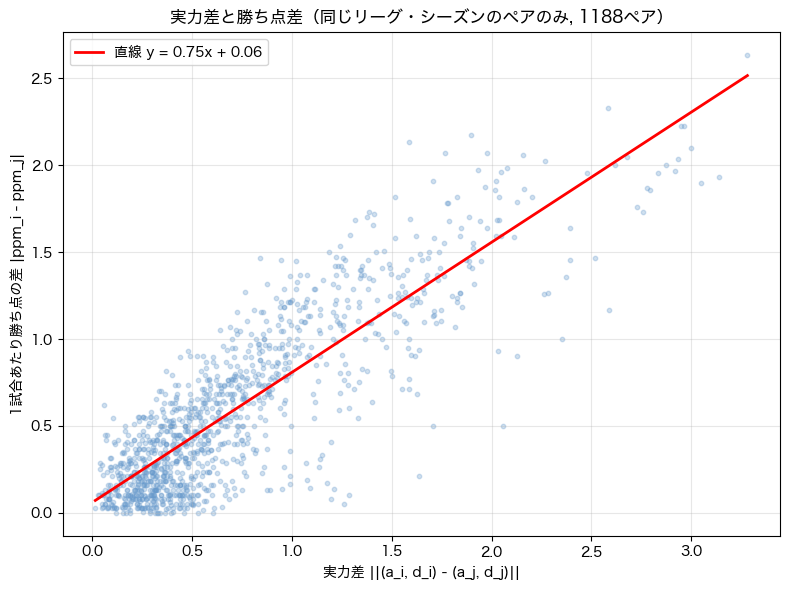

In [7]:
slope, intercept = np.polyfit(skill_gap, point_gap, 1)
x_line = np.linspace(skill_gap.min(), skill_gap.max(), 100)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(skill_gap, point_gap, s=10, alpha=0.3, color="#6699CC")
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=2, label=f"直線 y = {slope:.2f}x + {intercept:.2f}")
ax.set_xlabel("実力差 ||(a_i, d_i) - (a_j, d_j)||")
ax.set_ylabel("1試合あたり勝ち点の差 |ppm_i - ppm_j|")
ax.set_title(f"実力差と勝ち点差（同じリーグ・シーズンのペアのみ, {len(skill_gap)}ペア）")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 5. 相関を評価する

- ピアソンの相関係数：直線的な関係の強さ
- スピアマンの順位相関係数：順位だけを見た関係の強さ（外れ値や曲線的な関係に強い）

決定係数 $R^2$ は、ピアソンの相関係数の2乗で、直線で勝ち点差のばらつきのどれくらいを説明できるかを表す。

注意：1つのチームが何十ものペアに登場するので、ペアどうしは独立ではない。
そのため、p値は実際より小さく出る。p値よりも相関係数の大きさを見る。

In [8]:
pearson_r, pearson_p = stats.pearsonr(skill_gap, point_gap)
spearman_r, spearman_p = stats.spearmanr(skill_gap, point_gap)

print(f"ピアソン相関係数  r   = {pearson_r:.3f}  (p = {pearson_p:.2e})")
print(f"決定係数          R^2 = {pearson_r ** 2:.3f}")
print(f"スピアマン相関係数 rho = {spearman_r:.3f}  (p = {spearman_p:.2e})")

ピアソン相関係数  r   = 0.857  (p = 0.00e+00)
決定係数          R^2 = 0.735
スピアマン相関係数 rho = 0.796  (p = 6.85e-261)


### リーグ・シーズン別の相関係数

リーグ・シーズンごとに、相関係数を1つずつ出す。

In [9]:
rows = []
for name in sorted(set(league_season)):
    mask = pair_league == name
    x = skill_gap[mask]
    y = point_gap[mask]
    rows.append({
        "league_season": name,
        "チーム数": int((league_season == name).sum()),
        "ペア数": int(mask.sum()),
        "ピアソンr": stats.pearsonr(x, y)[0],
        "スピアマンrho": stats.spearmanr(x, y)[0],
    })

corr_table = pd.DataFrame(rows).set_index("league_season")
corr_table.round(3)

,チーム数,ペア数,ピアソンr,スピアマンrho
league_season,,,,
ISL2122,11,55,0.815,0.810
L11516,20,190,0.861,0.668
LF2324,16,120,0.836,0.842
LL1516,20,190,0.838,0.718
PL1516,20,190,0.804,0.748
SA1516,20,190,0.917,0.855
WSL1819,11,55,0.922,0.911
WSL1920,12,66,0.752,0.750
WSL2021,12,66,0.869,0.845


## 6. 守備力を 1/d にした場合

$d$ は「失点しやすさ」で、大きいほど守備が弱い。
その逆数 $1/d$ にすると、**大きいほど守備が強い**という向きになる。
$d$ が 0 に近いチームでは、$1/d$ がとても大きくなる点に注意する。

$$
\text{実力差} = \left\| (a_i, 1/d_i) - (a_j, 1/d_j) \right\| = \sqrt{(a_i - a_j)^2 + (1/d_i - 1/d_j)^2}
$$

勝ち点差は前と同じ $|\text{ppm}_i - \text{ppm}_j|$ で、同じリーグ・同じシーズンのペアだけを使う。

In [10]:
# 守備力の逆数
defence_inv = 1 / defence

# 実力差：(a, 1/d) 平面上の距離（ペアは上の idx_i, idx_j をそのまま使う）
skill_gap_inv = np.sqrt((attack[idx_i] - attack[idx_j]) ** 2 + (defence_inv[idx_i] - defence_inv[idx_j]) ** 2)

# 勝ち点差は上の point_gap をそのまま使う
print("defence_inv の最小・最大:", defence_inv.min().round(3), defence_inv.max().round(3))
print("skill_gap_inv の形:", skill_gap_inv.shape)

defence_inv の最小・最大: 0.327 10.925
skill_gap_inv の形: (1188,)


### 散布図

findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto

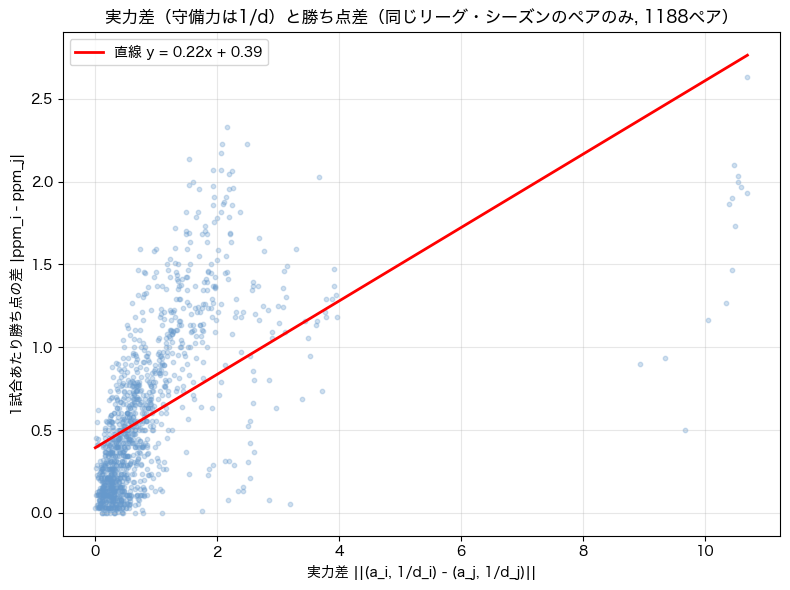

In [11]:
slope_inv, intercept_inv = np.polyfit(skill_gap_inv, point_gap, 1)
x_line_inv = np.linspace(skill_gap_inv.min(), skill_gap_inv.max(), 100)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(skill_gap_inv, point_gap, s=10, alpha=0.3, color="#6699CC")
ax.plot(x_line_inv, slope_inv * x_line_inv + intercept_inv, color="red", linewidth=2, label=f"直線 y = {slope_inv:.2f}x + {intercept_inv:.2f}")
ax.set_xlabel("実力差 ||(a_i, 1/d_i) - (a_j, 1/d_j)||")
ax.set_ylabel("1試合あたり勝ち点の差 |ppm_i - ppm_j|")
ax.set_title(f"実力差（守備力は1/d）と勝ち点差（同じリーグ・シーズンのペアのみ, {len(skill_gap_inv)}ペア）")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### 相関

In [12]:
pearson_r_inv, pearson_p_inv = stats.pearsonr(skill_gap_inv, point_gap)
spearman_r_inv, spearman_p_inv = stats.spearmanr(skill_gap_inv, point_gap)

print(f"ピアソン相関係数  r   = {pearson_r_inv:.3f}  (p = {pearson_p_inv:.2e})")
print(f"決定係数          R^2 = {pearson_r_inv ** 2:.3f}")
print(f"スピアマン相関係数 rho = {spearman_r_inv:.3f}  (p = {spearman_p_inv:.2e})")

ピアソン相関係数  r   = 0.575  (p = 1.60e-105)
決定係数          R^2 = 0.331
スピアマン相関係数 rho = 0.727  (p = 8.01e-196)


### リーグ・シーズン別の相関係数

In [13]:
rows = []
for name in sorted(set(league_season)):
    mask = pair_league == name
    x = skill_gap_inv[mask]
    y = point_gap[mask]
    rows.append({
        "league_season": name,
        "チーム数": int((league_season == name).sum()),
        "ペア数": int(mask.sum()),
        "ピアソンr": stats.pearsonr(x, y)[0],
        "スピアマンrho": stats.spearmanr(x, y)[0],
    })

corr_table_inv = pd.DataFrame(rows).set_index("league_season")
corr_table_inv.round(3)

,チーム数,ペア数,ピアソンr,スピアマンrho
league_season,,,,
ISL2122,11,55,0.826,0.807
L11516,20,190,0.652,0.539
LF2324,16,120,0.645,0.818
LL1516,20,190,0.754,0.706
PL1516,20,190,0.831,0.799
SA1516,20,190,0.836,0.860
WSL1819,11,55,0.873,0.859
WSL1920,12,66,0.864,0.845
WSL2021,12,66,0.898,0.876


## 7. iからjに対する差（向きあり）

ここまでは距離と絶対値だったので、「どちらが強いか」という向きは消えていた。
今度は、チーム $i$ から見たチーム $j$ との差を、符号つきで調べる。

$$
\text{勝ち点差}_{ij} = \text{ppm}_i - \text{ppm}_j
$$

$$
\text{実力差}_{ij} = a_i d_j - a_j d_i
$$

- $a_i d_j$：$i$ の攻撃力 × $j$ の守備の弱さ。$i$ が $j$ から点を取りやすい度合い
- $a_j d_i$：$j$ の攻撃力 × $i$ の守備の弱さ。$j$ が $i$ から点を取りやすい度合い

なので、$a_i d_j - a_j d_i$ が正なら、$i$ のほうが優勢という意味になる。
勝ち点は、これまでと同じ **1試合あたり** の値（ppm）を使う。

$(i, j)$ と $(j, i)$ は符号が逆になるだけなので、両方向を全部入れる（ペアの数は前の2倍になる）。
これもこれまでと同じく、同じリーグ・同じシーズンのペアだけを使う。

In [14]:
# i != j の全ての組（向きあり）で、同じリーグ・シーズンのものだけ残す
ii, jj = np.meshgrid(np.arange(n_teams), np.arange(n_teams), indexing="ij")
ii = ii.ravel()
jj = jj.ravel()
keep = (ii != jj) & (league_season[ii] == league_season[jj])
ii = ii[keep]
jj = jj[keep]
print("ペアの数（向きあり）:", len(ii))

# i から見た j との差
skill_diff = attack[ii] * defence[jj] - attack[jj] * defence[ii]
point_diff = ppm[ii] - ppm[jj]

print("skill_diff の形:", skill_diff.shape)
print("point_diff の形:", point_diff.shape)

ペアの数（向きあり）: 2376
skill_diff の形: (2376,)
point_diff の形: (2376,)


### 散布図

横軸を $a_i d_j - a_j d_i$、縦軸を $\text{ppm}_i - \text{ppm}_j$ にする。
$(i, j)$ と $(j, i)$ を両方入れているので、点は原点について対称に並ぶ。

findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Yu Gothic' not found.
findfont: Font family 'Meiryo' not found.
findfont: Font family 'Noto

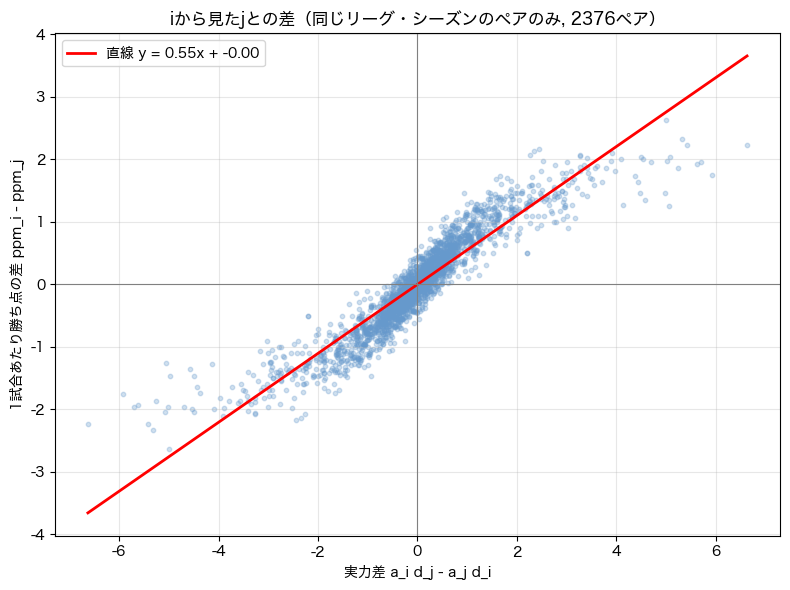

In [15]:
slope_d, intercept_d = np.polyfit(skill_diff, point_diff, 1)
x_line_d = np.linspace(skill_diff.min(), skill_diff.max(), 100)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(skill_diff, point_diff, s=10, alpha=0.3, color="#6699CC")
ax.plot(x_line_d, slope_d * x_line_d + intercept_d, color="red", linewidth=2, label=f"直線 y = {slope_d:.2f}x + {intercept_d:.2f}")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set_xlabel("実力差 a_i d_j - a_j d_i")
ax.set_ylabel("1試合あたり勝ち点の差 ppm_i - ppm_j")
ax.set_title(f"iから見たjとの差（同じリーグ・シーズンのペアのみ, {len(ii)}ペア）")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### 相関

距離のときと同じように、ピアソンとスピアマンの相関係数を出す。
向きありの場合は、(i, j) と (j, i) が必ず1組ずつ入っているので、符号の一致率（実力差と勝ち点差の符号が同じペアの割合）も見る。

In [16]:
pearson_r_d, pearson_p_d = stats.pearsonr(skill_diff, point_diff)
spearman_r_d, spearman_p_d = stats.spearmanr(skill_diff, point_diff)

print(f"ピアソン相関係数  r   = {pearson_r_d:.3f}  (p = {pearson_p_d:.2e})")
print(f"決定係数          R^2 = {pearson_r_d ** 2:.3f}")
print(f"スピアマン相関係数 rho = {spearman_r_d:.3f}  (p = {spearman_p_d:.2e})")

# 符号が同じペアの割合（どちらかが 0 のペアは除く）
nonzero = (skill_diff != 0) & (point_diff != 0)
same_sign = np.sign(skill_diff[nonzero]) == np.sign(point_diff[nonzero])
print(f"符号が一致したペアの割合: {same_sign.mean():.3f}  ({nonzero.sum()}ペア中)")

ピアソン相関係数  r   = 0.926  (p = 0.00e+00)
決定係数          R^2 = 0.857
スピアマン相関係数 rho = 0.955  (p = 0.00e+00)
符号が一致したペアの割合: 0.907  (2348ペア中)


### リーグ・シーズン別の相関係数

In [17]:
pair_league_d = league_season[ii]

rows = []
for name in sorted(set(league_season)):
    mask = pair_league_d == name
    x = skill_diff[mask]
    y = point_diff[mask]
    rows.append({
        "league_season": name,
        "チーム数": int((league_season == name).sum()),
        "ペア数": int(mask.sum()),
        "ピアソンr": stats.pearsonr(x, y)[0],
        "スピアマンrho": stats.spearmanr(x, y)[0],
    })

corr_table_d = pd.DataFrame(rows).set_index("league_season")
corr_table_d.round(3)

,チーム数,ペア数,ピアソンr,スピアマンrho
league_season,,,,
ISL2122,11,110,0.954,0.961
L11516,20,380,0.938,0.903
LF2324,16,240,0.921,0.963
LL1516,20,380,0.928,0.925
PL1516,20,380,0.954,0.958
SA1516,20,380,0.974,0.975
WSL1819,11,110,0.964,0.971
WSL1920,12,132,0.909,0.947
WSL2021,12,132,0.966,0.971
